# PDP Strikethrough vs Clean Pricing — A/B read-out

**Experiment 201 · ecom · Product Detail Page · 28-day run · 7-day per-customer conversion window**

Merchandising wants a struck-through MRP + "Save X%" badge on the PDP (urgency → conversion). Brand pushes back (cheapens us, attracts deal-seekers who churn). This notebook settles it — and the answer is more useful than either side expected: **the lift is real, but it comes with a refund cost, so we ship it where it wins and watch the guardrails.**

In [1]:
from pathlib import Path
import sys, duckdb, pandas as pd
from IPython.display import Image

ROOT = Path.cwd()
while not (ROOT / "seed_experiment.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "analysis")); sys.path.insert(0, str(ROOT))
import stats as ab
import make_figures as mk

con = duckdb.connect(str(ROOT / "data" / "experiment.duckdb"), read_only=True)
sql = lambda f: con.execute((ROOT / "sql" / f).read_text()).df()
FIG = ROOT / "figures"

# render the figures from the data so notebook and README never drift
mk.apply_theme(); _a,_o = mk._load_tables(); M = mk.compute_metrics(mk._customer_outcomes(_a,_o))
mk.fig1_forest(M); mk.fig2_dumbbell(M); mk.fig3_guardrails(M)
print("figures rendered from data")

figures rendered from data


## 1. First check: did the split actually come out 50/50?
A quick sanity check before trusting anything — if the traffic split is off, the randomization is broken and every number below is suspect.

In [2]:
srm = sql("01_srm_check.sql"); display(srm)
n_c=int(srm.loc[srm.variant_name=="control","n"].iloc[0]); n_t=int(srm.loc[srm.variant_name=="treatment","n"].iloc[0])
chi2,p_srm = ab.chisq_srm(n_c,n_t)
print(f"split {n_c:,}/{n_t:,} — chi-square p = {p_srm:.2f} → balanced, good to go.")

,variant_name,n,total,observed_share,expected_share
0,control,25047,50000.0,0.5009,0.5
1,treatment,24953,50000.0,0.4991,0.5


split 25,047/24,953 — chi-square p = 0.67 → balanced, good to go.


## 2. Primary metric — conversion rate, lift, and significance
We randomize at the **customer**, so we measure at the customer: did each assigned customer place ≥1 paid order within 7 days. We count **everyone we assigned** (intent-to-treat), and report the lift with a 95% confidence interval — a point estimate alone doesn't tell you if it's solid.

In [3]:
m = sql("03_per_variant_metrics.sql").set_index("variant_name"); display(m)
x_c,x_t = int(m.loc["control","converters"]), int(m.loc["treatment","converters"])
N_c,N_t = int(m.loc["control","customers"]), int(m.loc["treatment","customers"])
r = ab.lift_with_ci(x_c,N_c,x_t,N_t)
print(f"Control {r.p_control:.2%}  vs  Treatment {r.p_treatment:.2%}")
print(f"Lift {r.rel_lift:+.1%} relative ({r.abs_lift*100:+.2f}pp)  ·  95% CI {r.rel_ci[0]:+.1%}…{r.rel_ci[1]:+.1%}")
print(f"Two-proportion z-test: Z = {r.z:.2f}, p = {r.p_value:.3f}  → significant, and the CI clears zero.")

,customers,converters,conversion_rate,revenue,revenue_per_customer,aov,refund_rate,repeat_30d_rate,pmt_failure_rate
variant_name,,,,,,,,,
control,25047,957.0,0.0382,2800672.0,111.82,2926.51,0.0104,0.2257,0.0162
treatment,24953,1066.0,0.0427,2871193.0,115.06,2693.43,0.0206,0.1904,0.0174


Control 3.82%  vs  Treatment 4.27%
Lift +11.8% relative (+0.45pp)  ·  95% CI +2.8%…+20.9%
Two-proportion z-test: Z = 2.56, p = 0.010  → significant, and the CI clears zero.


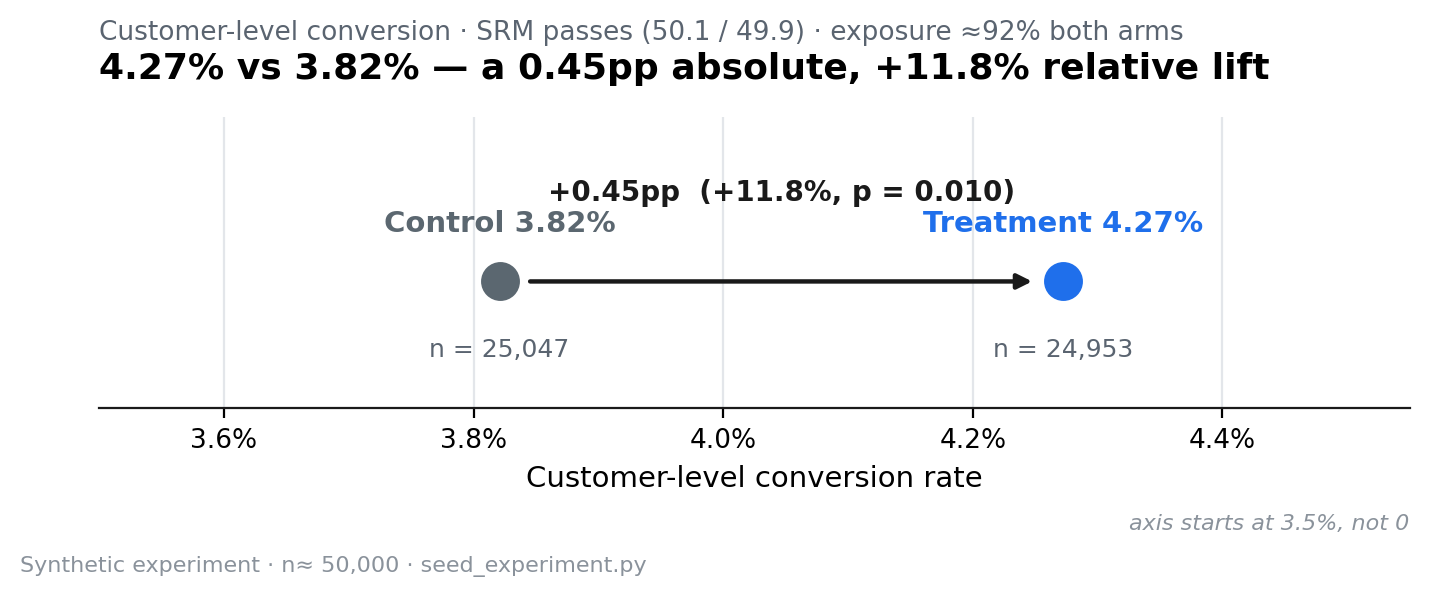

In [4]:
Image(filename=str(FIG/"02_conversion_compare.png"))

## 3. Was the test big enough? (sample size & MDE)
The change is cheap to build, so the bar isn't break-even — it's being able to detect an effect in the range strikethrough realistically produces (~3–12% relative). Quick check that our sample could.

In [5]:
baseline = r.p_control
n_needed = ab.required_sample_per_arm(baseline, mde_abs=0.005)   # detect a 0.5pp (~13% rel) effect
print(f"To detect a ~13% relative lift at 80% power we'd need ~{n_needed:,} customers per arm.")
print(f"We had ~{N_c:,} per arm — comfortably powered for the effect band we cared about.")

To detect a ~13% relative lift at 80% power we'd need ~24,517 customers per arm.
We had ~25,047 per arm — comfortably powered for the effect band we cared about.


## 4. Where does the lift come from? (segmentation by category)
The headline can hide a split. Cutting by category shows the effect is **not uniform** — and that's the actionable finding.

In [6]:
seg = sql("04_segmentation.sql")
rows=[]
for s in sorted(seg[seg.cut=="category"]["segment"].unique()):
    d=seg[(seg.cut=="category")&(seg.segment==s)]
    cc=d[d.variant_name=="control"]; tt=d[d.variant_name=="treatment"]
    res=ab.lift_with_ci(int(cc.converters.iloc[0]),int(cc.customers.iloc[0]),
                        int(tt.converters.iloc[0]),int(tt.customers.iloc[0]))
    rows.append({"segment":s,"control":f"{res.p_control:.2%}","treatment":f"{res.p_treatment:.2%}",
                 "rel_lift":f"{res.rel_lift:+.1%}","p":round(res.p_value,3),
                 "significant":res.p_value<0.05})
display(pd.DataFrame(rows))

,segment,control,treatment,rel_lift,p,significant
0,apparel_beauty,4.38%,5.00%,+14.3%,0.019,True
1,electronics,2.86%,2.78%,-2.7%,0.796,False
2,home,3.66%,4.29%,+17.3%,0.071,False


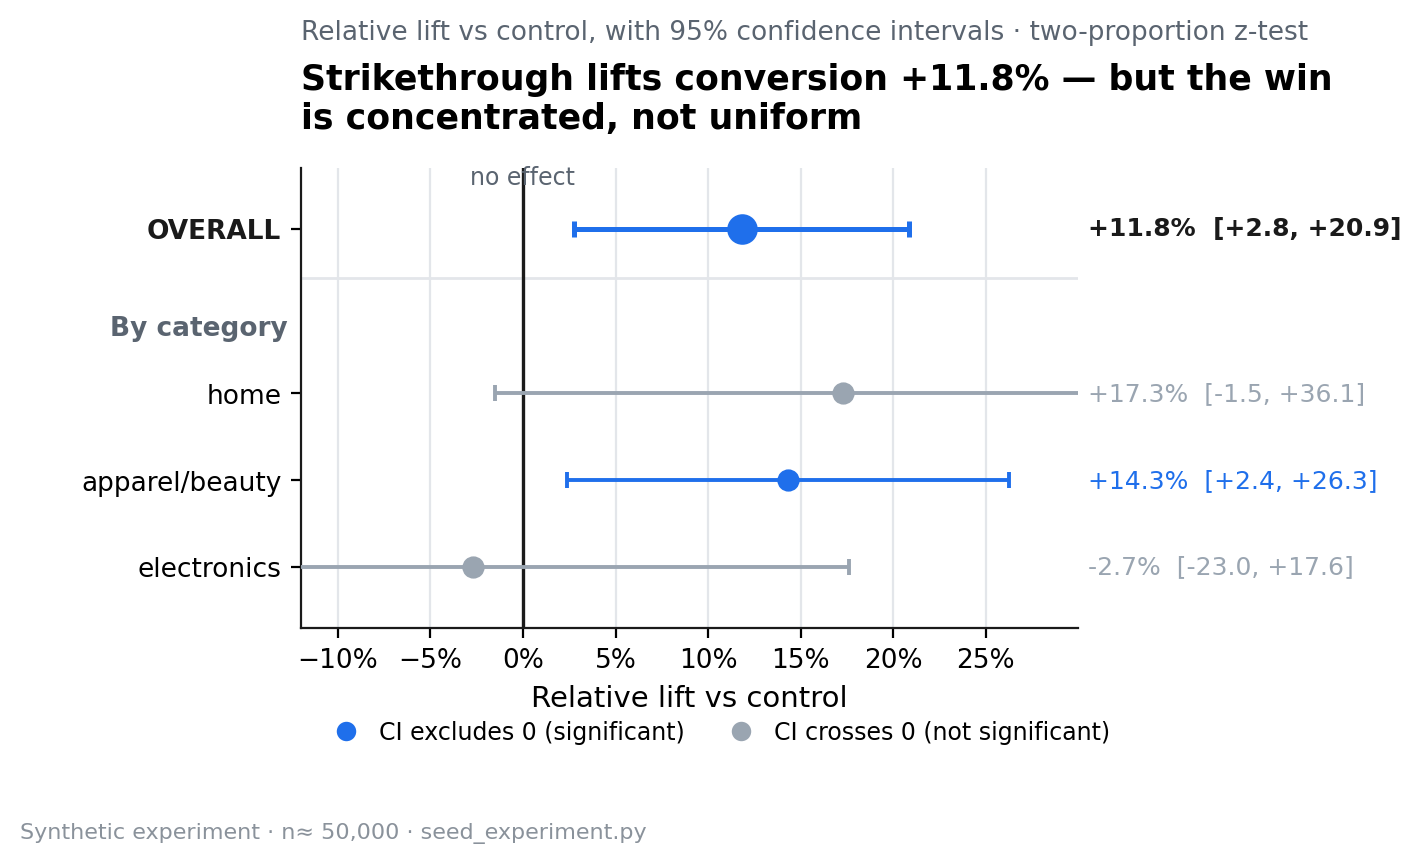

In [7]:
Image(filename=str(FIG/"01_lift_forest.png"))

**Read:** the win is **apparel/beauty** (+14%, significant) — discount framing works on deal-seeking categories. **Electronics is flat-to-negative** — the brand team's worry is right for premium goods. Home is positive but noisier (its CI crosses zero), so we treat it as "watch", not "ship". One headline number would have hidden all of this.

## 5. Guardrails — is the lift free? (no.)
A conversion win you'd expect side-effects from. We track the metrics we *don't* want to move, and two of them did.

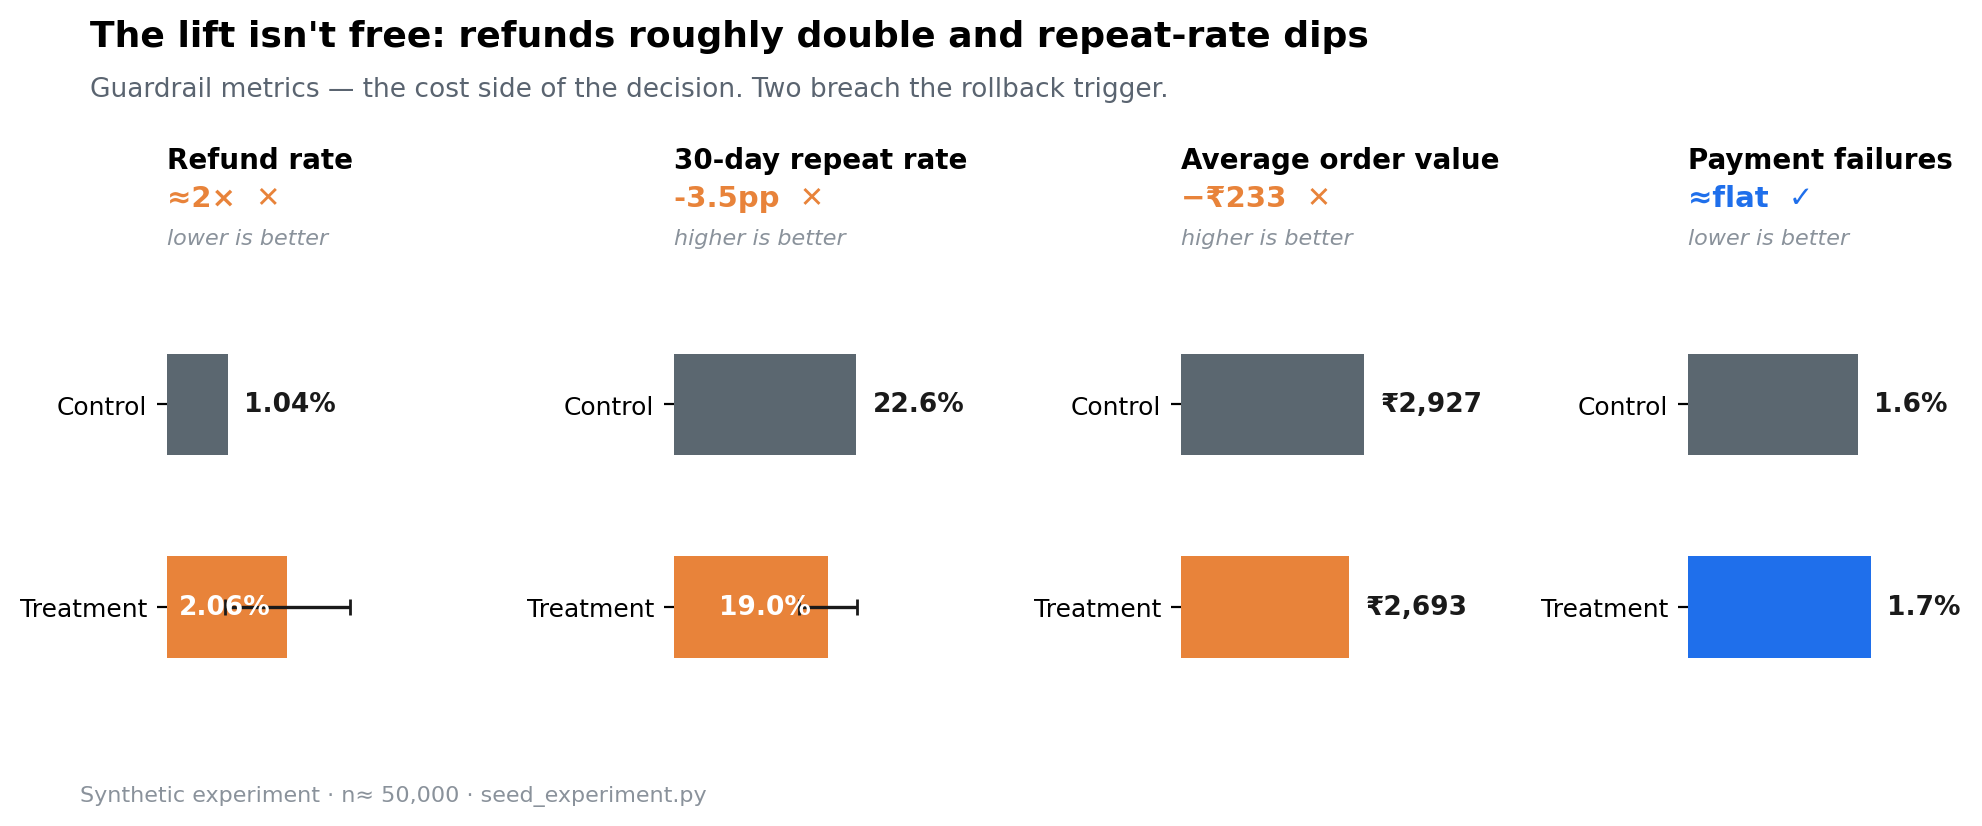

In [8]:
Image(filename=str(FIG/"03_guardrails.png"))

In [9]:
print(f"Refund rate    {m.loc['control','refund_rate']:.2%} → {m.loc['treatment','refund_rate']:.2%}   (roughly doubles)")
print(f"30-day repeat  {m.loc['control','repeat_30d_rate']:.1%} → {m.loc['treatment','repeat_30d_rate']:.1%}   (dips ~3.5pp)")
print(f"AOV            ₹{m.loc['control','aov']:,.0f} → ₹{m.loc['treatment','aov']:,.0f}   (smaller baskets)")
print(f"Payment fails  {m.loc['control','pmt_failure_rate']:.1%} → {m.loc['treatment','pmt_failure_rate']:.1%}   (flat — sanity OK)")
print()
print("Refund + repeat moving the wrong way is the reason this isn't a blanket 'ship'.")

Refund rate    1.04% → 2.06%   (roughly doubles)
30-day repeat  22.6% → 19.0%   (dips ~3.5pp)
AOV            ₹2,927 → ₹2,693   (smaller baskets)
Payment fails  1.6% → 1.7%   (flat — sanity OK)

Refund + repeat moving the wrong way is the reason this isn't a blanket 'ship'.


## 6. Does it move the North Star? (revenue per customer)
Conversion is the lever; the business metric it ladders up to is **revenue per customer**. It's up — but the refund and basket-size effects claw some of it back, which is exactly why the guardrails gate the decision.

In [10]:
rpc_c, rpc_t = m.loc["control","revenue_per_customer"], m.loc["treatment","revenue_per_customer"]
print(f"Revenue per customer: ₹{rpc_c:,.2f} (control) → ₹{rpc_t:,.2f} (treatment)  =  {rpc_t/rpc_c-1:+.1%}")
print("Positive and directionally consistent with the conversion lift — but read it net of the higher")
print("refund rate and lower repeat-rate before banking it. North Star up, with a cost to manage.")

Revenue per customer: ₹111.82 (control) → ₹115.06 (treatment)  =  +2.9%
Positive and directionally consistent with the conversion lift — but read it net of the higher
refund rate and lower repeat-rate before banking it. North Star up, with a cost to manage.


## 7. Verdict

- **It works, and it's significant:** +11.8% conversion (Z = 2.56, p = 0.010, 95% CI +2.8%…+20.9%), revenue per customer up ~3%.
- **But it isn't free:** refunds roughly double and 30-day repeat dips ~3.5pp — so it's not a blanket ship.
- **The win is concentrated:** apparel/beauty (+14%, significant); electronics flat-to-negative; home unproven.

**Recommendation:** ship strikethrough to **apparel/beauty**, where it clearly wins, with a **refund-rate alarm** (pause if refund > 3.0% sustained 3+ days). **Hold electronics** on clean pricing (no gain, worse repeat) and **watch home** for more data. Full reasoning, money sizing, and rollout in **[`decision_memo.md`](../decision_memo.md)**.